In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
%pip install matplotlib
import matplotlib.pyplot as plt  # type: ignore
%pip install seaborn
import seaborn as sns  # type: ignore

# Cargar datos
# Buscar el archivo en las ubicaciones posibles según el directorio de trabajo
candidates = [
    Path('../data/telco_churn.csv'),  # cwd = notebooks/
    Path('data/telco_churn.csv'),     # cwd = raíz del proyecto
]

csv_path = next((p for p in candidates if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError(
        "No se encontró 'telco_churn.csv'. "
        "Verifica que exista en la carpeta 'data' del proyecto."
    )

df = pd.read_csv(csv_path)

print(f"✅ Dataset: {df.shape[0]} filas, {df.shape[1]} columnas")
df.head()

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
✅ Dataset: 7043 filas, 21 columnas


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Información general del dataset
print("📊 INFORMACIÓN GENERAL DEL DATASET\n")
df.info()

print("\n" + "="*50 + "\n")

# Resumen de valores nulos por columna
print("🔍 VALORES NULOS POR COLUMNA:\n")
print(df.isnull().sum())

📊 INFORMACIÓN GENERAL DEL DATASET

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  

In [3]:
# Estadísticas descriptivas solo de columnas numéricas
print("📈 ESTADÍSTICAS DESCRIPTIVAS (Variables Numéricas):\n")
display(df.describe())

📈 ESTADÍSTICAS DESCRIPTIVAS (Variables Numéricas):



,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


🎯 DISTRIBUCIÓN DE LA VARIABLE OBJETIVO (Churn):

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Porcentajes:
Churn
No     73.0
Yes    27.0
Name: proportion, dtype: float64


C:\Users\user\AppData\Local\Temp\ipykernel_2672\1339008582.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', palette='Set2')


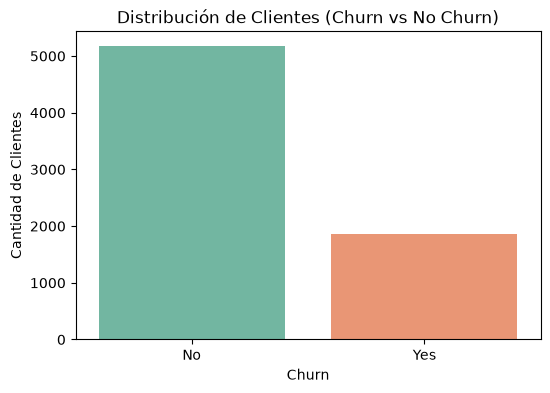

In [4]:
# Distribución de la variable objetivo 'Churn'
print("🎯 DISTRIBUCIÓN DE LA VARIABLE OBJETIVO (Churn):\n")
print(df['Churn'].value_counts())

print("\nPorcentajes:")
print(df['Churn'].value_counts(normalize=True).round(2) * 100)

# Gráfico de barras
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn', palette='Set2')
plt.title('Distribución de Clientes (Churn vs No Churn)')
plt.xlabel('Churn')
plt.ylabel('Cantidad de Clientes')
plt.show()

In [5]:
# Verificar el tipo de dato de TotalCharges
print("Tipo de dato actual de 'TotalCharges':", df['TotalCharges'].dtype)

# A veces, TotalCharges tiene espacios en blanco y se lee como texto (object).
# Vamos a convertirlo a numérico, forzando los errores a NaN (nulos) para manejarlos después.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("Tipo de dato después de la conversión:", df['TotalCharges'].dtype)
print(f"Valores nulos nuevos en TotalCharges: {df['TotalCharges'].isnull().sum()}")

Tipo de dato actual de 'TotalCharges': str
Tipo de dato después de la conversión: float64
Valores nulos nuevos en TotalCharges: 11


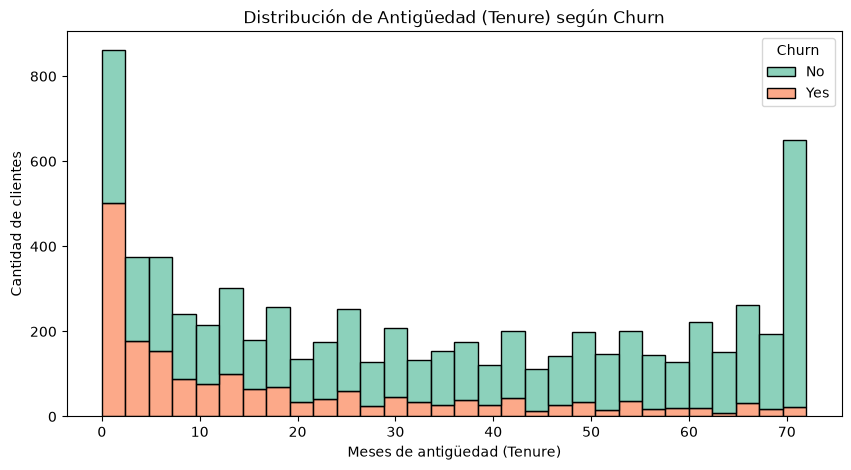

In [6]:
plt.figure(figsize=(10, 5))
# Usamos un histograma apilado para comparar la distribución
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', bins=30, palette='Set2')
plt.title('Distribución de Antigüedad (Tenure) según Churn')
plt.xlabel('Meses de antigüedad (Tenure)')
plt.ylabel('Cantidad de clientes')
plt.show()

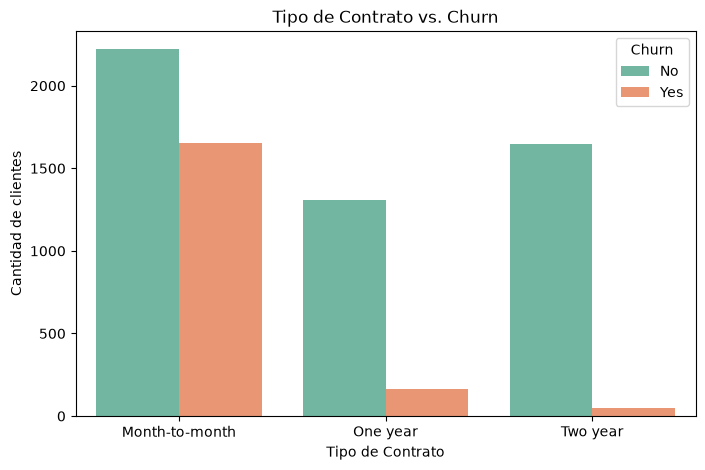

In [7]:
plt.figure(figsize=(8, 5))
# 'order' asegura que las barras salgan en un orden lógico
orden_contratos = ['Month-to-month', 'One year', 'Two year']
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set2', order=orden_contratos)
plt.title('Tipo de Contrato vs. Churn')
plt.xlabel('Tipo de Contrato')
plt.ylabel('Cantidad de clientes')
plt.show()

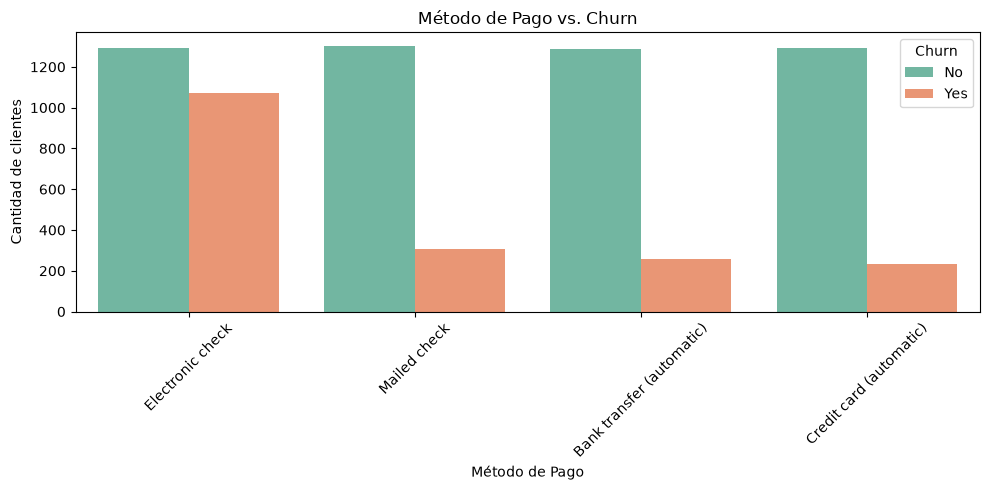

In [8]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='PaymentMethod', hue='Churn', palette='Set2')
plt.title('Método de Pago vs. Churn')
plt.xlabel('Método de Pago')
plt.ylabel('Cantidad de clientes')
plt.xticks(rotation=45) # Rotar etiquetas para que se lean bien
plt.tight_layout() # Ajustar márgenes
plt.show()

# 📝 Hallazgos Clave del EDA (Insights de Negocio)

Tras el análisis exploratorio del dataset de Telco Customer Churn (7,043 clientes, 21 variables), se identificaron los siguientes patrones críticos:

### 1. 🧹 Calidad de los Datos
- **TotalCharges**: Se encontraron 11 valores nulos. Tras investigar, corresponden a clientes con `tenure = 0` (registrados en el mes actual), por lo que aún no tienen un cargo total acumulado. Se imputarán con `0` en la fase de preprocesamiento.

### 2. 🎯 Variable Objetivo (Churn)
- La tasa de fuga es del **~26.5%**. Existe un desbalance moderado de clases, lo que sugiere que debemos priorizar métricas como **Recall** y **F1-Score** sobre la simple Accuracy al evaluar los modelos.

### 3. 📉 Antigüedad (Tenure)
- Existe una correlación inversa fuerte: los clientes con **menos de 6 meses** de antigüedad representan la gran mayoría de las bajas. El riesgo de fuga disminuye drásticamente después del primer año.

### 4. 📜 Tipo de Contrato (La variable más predictiva)
- Los clientes con contrato **Month-to-month** (mes a mes) tienen una tasa de fuga exponencialmente mayor en comparación con los contratos a 1 o 2 años. La falta de compromiso a largo plazo es el mayor indicador de riesgo.

### 5. 💳 Método de Pago
- El método **Electronic check** (cheque electrónico) presenta la proporción de fuga más alta, posiblemente por la fricción o falta de automatización en el cobro recurrente en comparación con métodos automáticos.

---
### 💡 Recomendación Preliminar de Negocio
Para reducir el Churn, las estrategias deben enfocarse en:
1. Incentivar la migración de contratos *Month-to-month* a contratos anuales (ej. ofreciendo un mes gratis o descuento).
2. Crear un programa de "Onboarding" o retención activa para los primeros 3 meses de antigüedad.
3. Promover métodos de pago automáticos sobre el cheque electrónico.

In [9]:
# 1. Verificar cuántos nulos hay antes de actuar
print("Nulos antes de limpiar:", df['TotalCharges'].isnull().sum())

# 2. Imputar los nulos con 0 (basado en que tenure == 0)
# Usamos .loc para ser precisos: donde tenure sea 0, TotalCharges será 0.
df.loc[df['tenure'] == 0, 'TotalCharges'] = 0

# 3. Verificar que ya no hay nulos
print("Nulos después de limpiar:", df['TotalCharges'].isnull().sum())

# Comprobación rápida
print("\n✅ Nulos en TotalCharges resueltos correctamente.")

Nulos antes de limpiar: 11
Nulos después de limpiar: 0

✅ Nulos en TotalCharges resueltos correctamente.


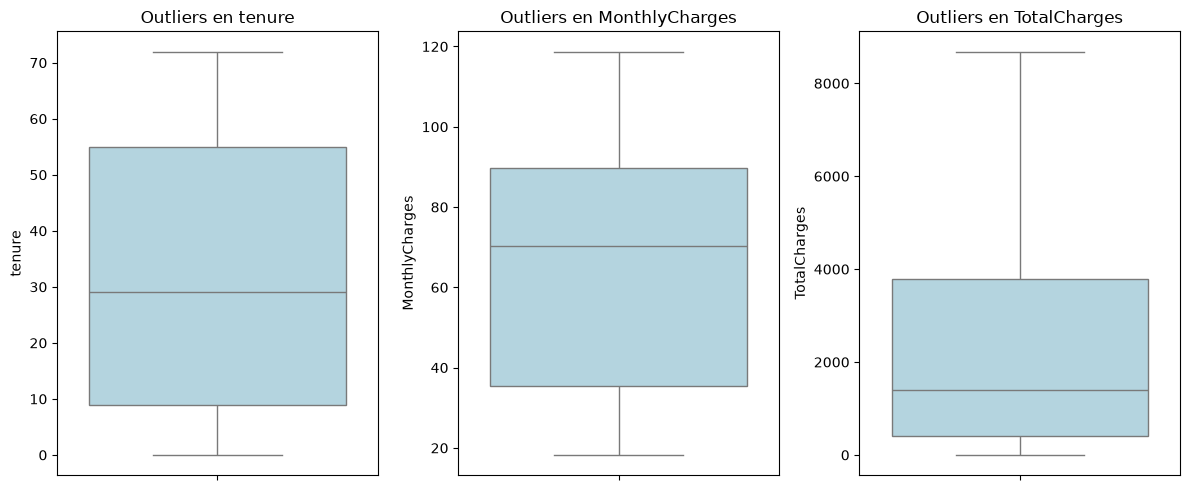

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionamos solo las columnas numéricas continuas para revisar
cols_numericas = ['tenure', 'MonthlyCharges', 'TotalCharges']

plt.figure(figsize=(12, 5))

# Creamos un boxplot (diagrama de caja) para cada una
for i, col in enumerate(cols_numericas):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=df[col], color='lightblue')
    plt.title(f'Outliers en {col}')
    plt.tight_layout()

plt.show()

In [11]:
# 1. Codificar la variable objetivo (Target) 'Churn' a 0 y 1
# 0 = No se va, 1 = Se va (Esto es crucial para el modelo)
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

# 2. Mapeo binario para variables de 2 categorías
columnas_binarias = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
mapeo_binario = {'No': 0, 'Yes': 1, 'Female': 0, 'Male': 1}

for col in columnas_binarias:
    df[col] = df[col].map(mapeo_binario)

# 3. One-Hot Encoding para variables con múltiples categorías
# pd.get_dummies crea columnas nuevas (ej: 'Contract_Month-to-month')
df_encoded = pd.get_dummies(
    df, 
    columns=[
        'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
        'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
        'Contract', 'PaymentMethod'
    ],
    drop_first=False # Mantenemos todas las categorías para que los árboles de decisión las capturen bien
)

# 4. Verificación del resultado
print(f"📊 Dimensiones originales: {df.shape}")
print(f"📊 Dimensiones después del Encoding: {df_encoded.shape}")
print("\n✅ Ejemplo de nuevas columnas creadas para 'Contract':")
print([col for col in df_encoded.columns if 'Contract' in col])

📊 Dimensiones originales: (7043, 21)
📊 Dimensiones después del Encoding: (7043, 42)

✅ Ejemplo de nuevas columnas creadas para 'Contract':
['Contract_Month-to-month', 'Contract_One year', 'Contract_Two year']


In [12]:
# 1. Crear una variable de 'Grupo de Antigüedad' (Tenure Group)
# Esto ayuda al modelo a capturar patrones no lineales (ej. el riesgo es alto al inicio, luego baja)
def crear_grupo_tenure(meses):
    if meses <= 12:
        return '0-12 meses'
    elif meses <= 24:
        return '13-24 meses'
    elif meses <= 48:
        return '25-48 meses'
    else:
        return '48+ meses'

df_encoded['TenureGroup'] = df_encoded['tenure'].apply(crear_grupo_tenure)

# 2. Aplicar One-Hot Encoding a esta nueva variable
df_encoded = pd.get_dummies(df_encoded, columns=['TenureGroup'], drop_first=False)

print("✅ Nueva variable 'TenureGroup' creada y codificada.")
print(f"📊 Nuevas dimensiones: {df_encoded.shape}")

✅ Nueva variable 'TenureGroup' creada y codificada.
📊 Nuevas dimensiones: (7043, 46)


In [13]:
from sklearn.model_selection import train_test_split

# 1. Definir X (features) e y (target)
# Eliminamos 'customerID' porque es un identificador único y no aporta al aprendizaje
X = df_encoded.drop(columns=['Churn', 'customerID'])
y = df_encoded['Churn']

# 2. Dividir en Train (80%) y Test (20%)
# stratify=y es CRUCIAL: asegura que la proporción de Churn (26.5%) se mantenga igual en ambos conjuntos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, # Para reproducibilidad
    stratify=y       # Mantiene el balance de clases
)

print(f"✅ Datos separados correctamente:")
print(f"   - X_train: {X_train.shape} (80% para entrenar)")
print(f"   - X_test:  {X_test.shape} (20% para evaluar)")
print(f"   - Proporción de Churn en y_train: {y_train.mean():.2%}")
print(f"   - Proporción de Churn en y_test:  {y_test.mean():.2%}")

✅ Datos separados correctamente:
   - X_train: (5634, 44) (80% para entrenar)
   - X_test:  (1409, 44) (20% para evaluar)
   - Proporción de Churn en y_train: 26.54%
   - Proporción de Churn en y_test:  26.54%


In [14]:
from sklearn.preprocessing import StandardScaler

# 1. Identificar las columnas numéricas continuas originales
cols_a_escalar = ['tenure', 'MonthlyCharges', 'TotalCharges']

# 2. Inicializar el escalador
scaler = StandardScaler()

# 3. Ajustar (fit) solo con los datos de entrenamiento y transformar (transform) ambos
# ¡NUNCA hagas fit sobre X_test! Eso sería "data leakage" (fuga de datos)
X_train[cols_a_escalar] = scaler.fit_transform(X_train[cols_a_escalar])
X_test[cols_a_escalar] = scaler.transform(X_test[cols_a_escalar])

print("✅ Escalado completado. Las variables numéricas ahora tienen media=0 y desviación=1.")

# Verificación rápida
print("\nMedia de 'TotalCharges' en X_train (debería ser ~0):", X_train['TotalCharges'].mean().round(5))

✅ Escalado completado. Las variables numéricas ahora tienen media=0 y desviación=1.

Media de 'TotalCharges' en X_train (debería ser ~0): 0.0


In [15]:
import numpy as np

# 1. Calcular la matriz de correlación de las variables numéricas
corr_matrix = X_train.corr().abs()

# 2. Obtener la mitad superior de la matriz (para no comparar una variable consigo misma ni duplicar)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# 3. Identificar columnas con una correlación mayor a 0.85 (umbral estándar)
to_drop = [column for column in upper.columns if any(upper[column] > 0.85)]

print(f"🔍 Variables altamente correlacionadas (>0.85) detectadas: {to_drop}")

# 4. Eliminar esas variables de nuestros conjuntos de datos
X_train = X_train.drop(columns=to_drop)
X_test = X_test.drop(columns=to_drop)

print(f"\n✅ Selección de variables completada.")
print(f"📊 Dimensiones finales de X_train: {X_train.shape}")
print(f"📊 Dimensiones finales de X_test:  {X_test.shape}")

🔍 Variables altamente correlacionadas (>0.85) detectadas: ['MultipleLines_No phone service', 'OnlineSecurity_No internet service', 'OnlineBackup_No internet service', 'DeviceProtection_No internet service', 'TechSupport_No internet service', 'StreamingTV_No internet service', 'StreamingMovies_No internet service', 'TenureGroup_48+ meses']

✅ Selección de variables completada.
📊 Dimensiones finales de X_train: (5634, 36)
📊 Dimensiones finales de X_test:  (1409, 36)


In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

def evaluar_modelo(modelo, X_train, y_train, X_test, y_test, nombre_modelo):
    # Entrenar
    modelo.fit(X_train, y_train)
    
    # Predecir
    y_pred = modelo.predict(X_test)
    
    # Calcular métricas
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    print(f"📊 Resultados para: {nombre_modelo}")
    print(f"   Accuracy : {acc:.4f}")
    print(f"   Precision: {prec:.4f}")
    print(f"   Recall   : {rec:.4f}  <-- ¡CRÍTICO para Churn!")
    print(f"   F1-Score : {f1:.4f}")
    print("-" * 40)
    
    return {'Modelo': nombre_modelo, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1}

In [18]:
from sklearn.linear_model import LogisticRegression

# Inicializamos con class_weight='balanced' para manejar el desbalance
log_reg = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)

resultados_logreg = evaluar_modelo(log_reg, X_train, y_train, X_test, y_test, "Regresión Logística")

📊 Resultados para: Regresión Logística
   Accuracy : 0.7331
   Precision: 0.4983
   Recall   : 0.7914  <-- ¡CRÍTICO para Churn!
   F1-Score : 0.6116
----------------------------------------


In [19]:
from sklearn.ensemble import RandomForestClassifier

# 100 árboles, profundidad limitada para evitar overfitting, y balanceo de clases
rf_model = RandomForestClassifier(
    n_estimators=100, 
    max_depth=10, 
    class_weight='balanced', 
    random_state=42, 
    n_jobs=-1 # Usa todos los núcleos de tu CPU
)

resultados_rf = evaluar_modelo(rf_model, X_train, y_train, X_test, y_test, "Random Forest")

📊 Resultados para: Random Forest
   Accuracy : 0.7637
   Precision: 0.5389
   Recall   : 0.7594  <-- ¡CRÍTICO para Churn!
   F1-Score : 0.6304
----------------------------------------


In [20]:
import xgboost as xgb

# Calcular el peso para la clase positiva (Churn = 1)
# Fórmula: (Números de No Churn) / (Números de Churn)
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=scale_weight, # Manejo del desbalance
    random_state=42,
    eval_metric='logloss'
)

resultados_xgb = evaluar_modelo(xgb_model, X_train, y_train, X_test, y_test, "XGBoost")

📊 Resultados para: XGBoost
   Accuracy : 0.7551
   Precision: 0.5263
   Recall   : 0.7754  <-- ¡CRÍTICO para Churn!
   F1-Score : 0.6270
----------------------------------------


In [21]:
import pandas as pd

# Crear un DataFrame con los resultados
df_resultados = pd.DataFrame([resultados_logreg, resultados_rf, resultados_xgb])

# Ordenar por F1-Score o Recall (lo que sea más importante para el negocio)
df_resultados = df_resultados.sort_values(by='Recall', ascending=False).reset_index(drop=True)

print("🏆 COMPARATIVA DE MODELOS (Ordenado por Recall)")
display(df_resultados.style.highlight_max(subset=['Accuracy', 'Precision', 'Recall', 'F1-Score'], color='lightgreen'))

🏆 COMPARATIVA DE MODELOS (Ordenado por Recall)


,Modelo,Accuracy,Precision,Recall,F1-Score
0,Regresión Logística,0.733144,0.498316,0.791444,0.611570
1,XGBoost,0.755145,0.526316,0.775401,0.627027
2,Random Forest,0.763662,0.538899,0.759358,0.630411


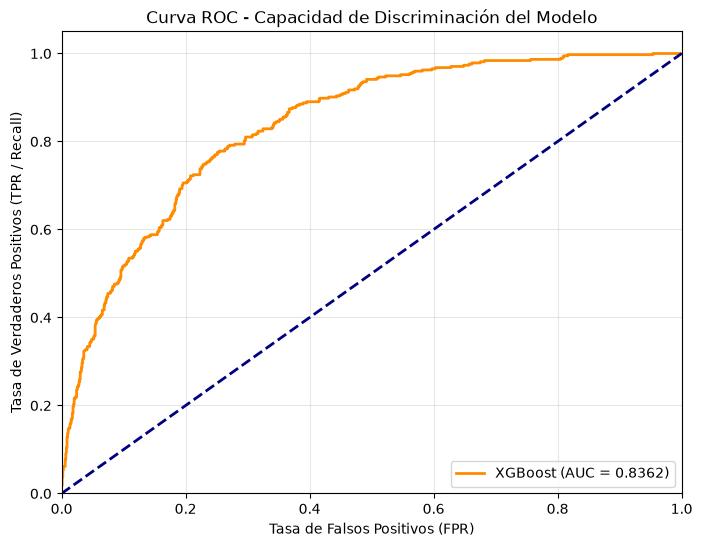

In [22]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Usaremos el modelo XGBoost de la Fase 4 (o el que haya ganado en tu tabla)
# Obtenemos las PROBABILIDADES de la clase positiva (Churn = 1)
y_pred_proba = xgb_model.predict_proba(X_test)[:, 1]

# Calcular FPR (Falsos Positivos) y TPR (Verdaderos Positivos / Recall)
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

# Graficar
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'XGBoost (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # Línea de azar
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR / Recall)')
plt.title('Curva ROC - Capacidad de Discriminación del Modelo')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

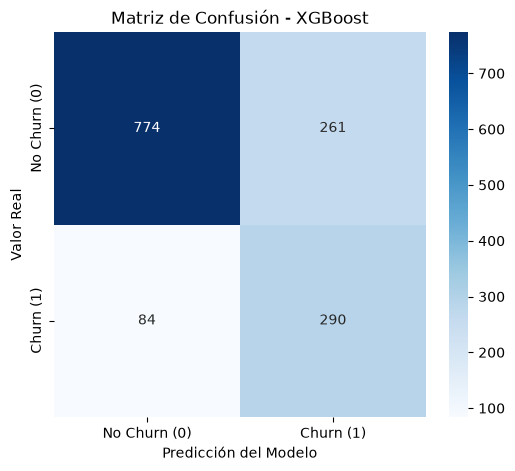


💡 INTERPRETACIÓN DE NEGOCIO:
• Verdaderos Negativos (TN): 774 clientes que predijimos que se quedarían y así fue.
• Falsos Positivos (FP): 261 clientes que predijimos que se irían, pero se quedaron. (Costo: descuento innecesario).
• Falsos Negativos (FN): 84 clientes que se fueron y NO los detectamos. (Costo: pérdida total del cliente y del ingreso).
• Verdaderos Positivos (TP): 290 clientes que se iban y logramos detectarlos a tiempo para retenerlos.


In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns

# Predecir con el modelo
y_pred = xgb_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

# Graficar
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Churn (0)', 'Churn (1)'], 
            yticklabels=['No Churn (0)', 'Churn (1)'])
plt.title('Matriz de Confusión - XGBoost')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.show()

# Explicación de negocio
print("\n💡 INTERPRETACIÓN DE NEGOCIO:")
print(f"• Verdaderos Negativos (TN): {cm[0,0]} clientes que predijimos que se quedarían y así fue.")
print(f"• Falsos Positivos (FP): {cm[0,1]} clientes que predijimos que se irían, pero se quedaron. (Costo: descuento innecesario).")
print(f"• Falsos Negativos (FN): {cm[1,0]} clientes que se fueron y NO los detectamos. (Costo: pérdida total del cliente y del ingreso).")
print(f"• Verdaderos Positivos (TP): {cm[1,1]} clientes que se iban y logramos detectarlos a tiempo para retenerlos.")

In [24]:
import optuna
from sklearn.metrics import f1_score

# 1. Definir la función objetivo que Optuna intentará maximizar
def objective(trial):
    # Definir el espacio de búsqueda de hiperparámetros
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 200),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
        'scale_pos_weight': scale_weight, # Mantenemos el balanceo de clases
        'random_state': 42,
        'eval_metric': 'logloss'
    }
    
    # Entrenar modelo con estos parámetros
    model = xgb.XGBClassifier(**params)
    model.fit(X_train, y_train)
    
    # Predecir y calcular la métrica a optimizar (F1-Score es un buen equilibrio)
    y_pred = model.predict(X_test)
    return f1_score(y_test, y_pred)

print("🔍 Iniciando optimización con Optuna (20 trials)... Esto puede tomar 1-2 minutos.")

# 2. Crear el estudio y optimizar (maximize porque queremos el F1-Score más alto)
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=20, show_progress_bar=True)

# 3. Mostrar los mejores parámetros encontrados
print("\n🏆 MEJORES HIPERPARÁMETROS ENCONTRADOS:")
for key, value in study.best_params.items():
    print(f"   {key}: {value}")
print(f"\n   Mejor F1-Score alcanzado: {study.best_value:.4f}")

[I 2026-10-14 14:11:31,762] A new study created in memory with name: no-name-c3ac0ce3-32b9-4571-b7ff-a186b8d8096a


🔍 Iniciando optimización con Optuna (20 trials)... Esto puede tomar 1-2 minutos.


  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-10-14 14:11:33,088] Trial 0 finished with value: 0.6165745856353592 and parameters: {'n_estimators': 105, 'max_depth': 5, 'learning_rate': 0.18454006696035985}. Best is trial 0 with value: 0.6165745856353592.
[I 2026-10-14 14:11:33,396] Trial 1 finished with value: 0.6058002148227712 and parameters: {'n_estimators': 113, 'max_depth': 3, 'learning_rate': 0.29140148399132804}. Best is trial 0 with value: 0.6165745856353592.
[I 2026-10-14 14:11:33,576] Trial 2 finished with value: 0.6217948717948718 and parameters: {'n_estimators': 60, 'max_depth': 5, 'learning_rate': 0.12471301700696392}. Best is trial 2 with value: 0.6217948717948718.
[I 2026-10-14 14:11:34,073] Trial 3 finished with value: 0.6223698781838317 and parameters: {'n_estimators': 193, 'max_depth': 6, 'learning_rate': 0.055076390152262664}. Best is trial 3 with value: 0.6223698781838317.
[I 2026-10-14 14:11:34,668] Trial 4 finished with value: 0.5868725868725869 and parameters: {'n_estimators': 169, 'max_depth': 10, '

In [25]:
# Entrenar el modelo final con los mejores parámetros
mejores_params = study.best_params
mejores_params['scale_pos_weight'] = scale_weight
mejores_params['random_state'] = 42
mejores_params['eval_metric'] = 'logloss'

xgb_final = xgb.XGBClassifier(**mejores_params)
xgb_final.fit(X_train, y_train)

print("✅ Modelo XGBoost Final entrenado y listo para la Fase 6 (Interpretabilidad).")

✅ Modelo XGBoost Final entrenado y listo para la Fase 6 (Interpretabilidad).


C:\Users\user\AppData\Local\Temp\ipykernel_2672\330304311.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=df_importancia.head(15), palette='viridis')


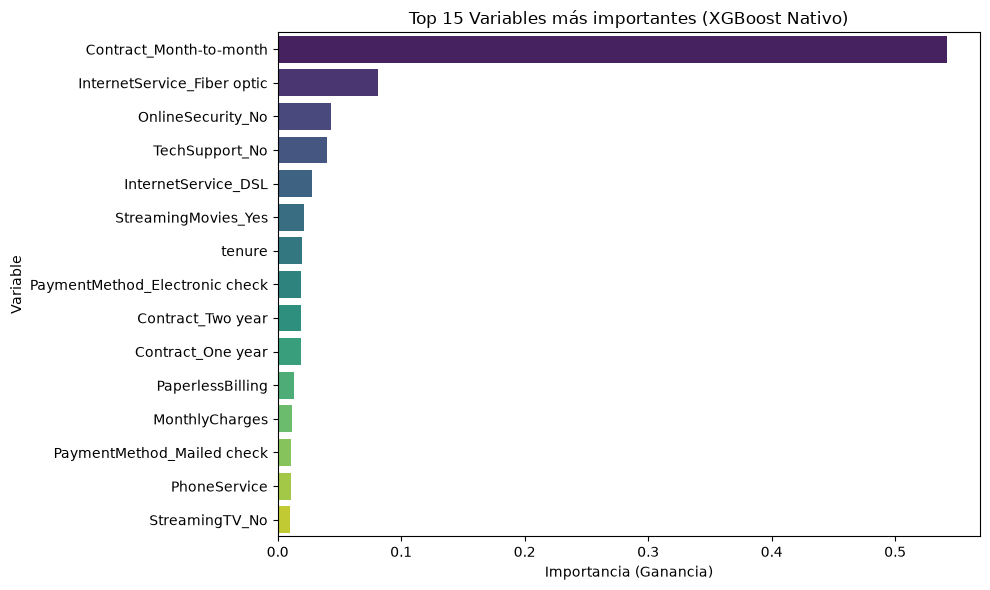

In [26]:
import matplotlib.pyplot as plt

# Extraer la importancia de las variables del modelo final
importancia = xgb_final.feature_importances_

# Crear un DataFrame para ordenar y visualizar
df_importancia = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importancia
}).sort_values(by='Importance', ascending=False)

# Graficar las top 15 variables más importantes
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=df_importancia.head(15), palette='viridis')
plt.title('Top 15 Variables más importantes (XGBoost Nativo)')
plt.xlabel('Importancia (Ganancia)')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

📊 Generando SHAP Summary Plot...


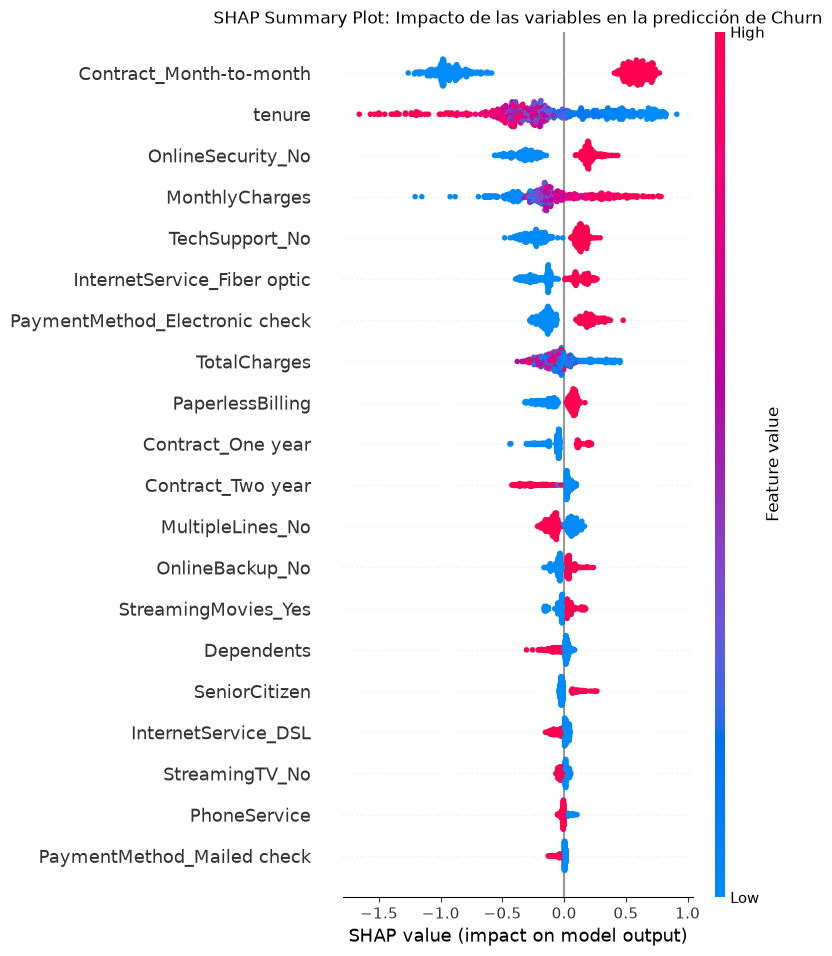

In [27]:
import shap

# Inicializar el objeto explicador de SHAP para Tree-based models (es muy rápido)
explainer = shap.TreeExplainer(xgb_final)

# Calcular los valores SHAP para el conjunto de prueba
# (Usamos una muestra de 500 para que el gráfico no se sature, aunque puedes usar X_test completo)
shap_values = explainer.shap_values(X_test.sample(500, random_state=42))

# Generar el Summary Plot (Gráfico de resumen)
print("📊 Generando SHAP Summary Plot...")
shap.summary_plot(shap_values, X_test.sample(500, random_state=42), show=False)
plt.title('SHAP Summary Plot: Impacto de las variables en la predicción de Churn')
plt.show()

👤 Analizando Cliente #50
   ¿Realmente se fue (Churn)? NO (0)
   Probabilidad predicha de fuga: 3.08%



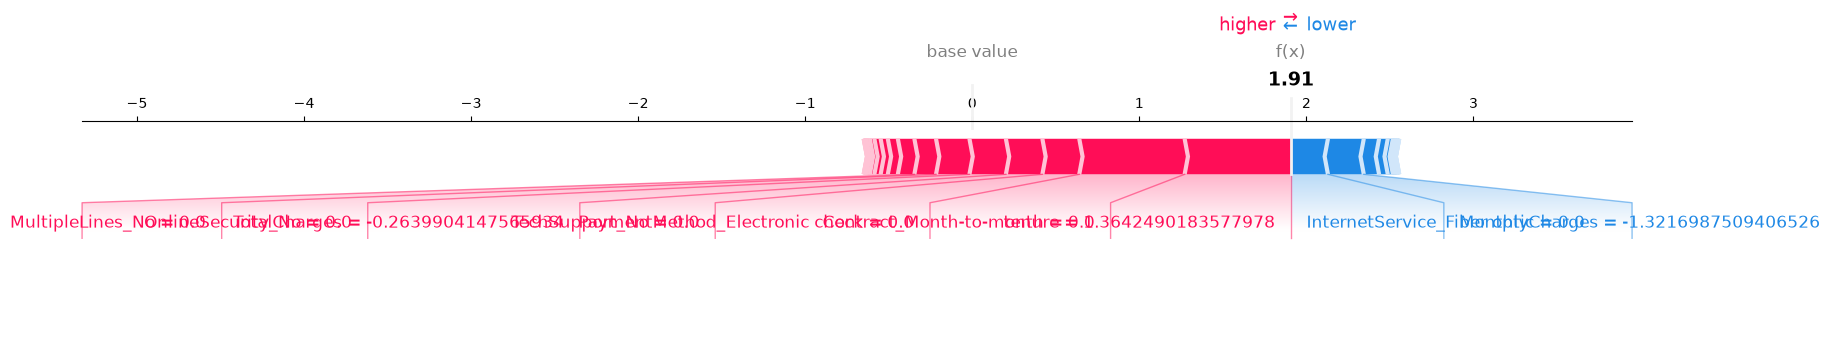

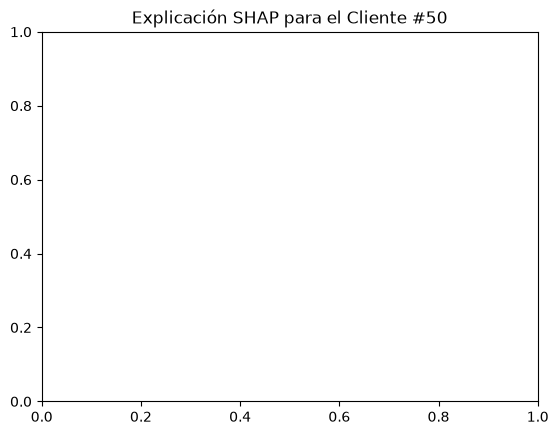

In [28]:
# Seleccionamos un cliente específico del conjunto de prueba (índice 50)
cliente_idx = 50
cliente_datos = X_test.iloc[cliente_idx]
cliente_real = y_test.iloc[cliente_idx]

print(f"👤 Analizando Cliente #{cliente_idx}")
print(f"   ¿Realmente se fue (Churn)? {'SÍ (1)' if cliente_real == 1 else 'NO (0)'}")
print(f"   Probabilidad predicha de fuga: {xgb_final.predict_proba(cliente_datos.values.reshape(1, -1))[0][1]:.2%}\n")

# Generar el Force Plot para este cliente
shap.initjs() # Necesario para renderizar el gráfico interactivo en Jupyter/VSCode
shap.force_plot(
    explainer.expected_value, 
    shap_values[cliente_idx], 
    cliente_datos,
    matplotlib=True
)
plt.title(f'Explicación SHAP para el Cliente #{cliente_idx}')
plt.show()

# 📝 Interpretabilidad del Modelo y Recomendaciones de Negocio

El uso de SHAP nos ha permitido validar que el modelo no es una "caja negra", sino que ha aprendido patrones lógicos y accionables:

### 1.  Factores de Riesgo Críticos (Aumentan la probabilidad de Churn)
- **Contrato Month-to-month:** Es el mayor impulsor de fuga. La falta de compromiso a largo plazo es el riesgo #1.
- **Servicio de Internet Fiber Optic:** Paradójicamente, los clientes con la conexión más rápida (y cara) se van más. Esto sugiere problemas de **soporte técnico, precio o inestabilidad** en este servicio específico.
- **Pago por Electronic Check:** Los clientes que pagan manualmente tienen más fricción y tienden a cancelar más que los que tienen débito automático.
- **Falta de Servicios Adicionales:** Los clientes que NO tienen `OnlineSecurity`, `TechSupport` o `StreamingTV` tienen mayor riesgo. (Efecto "Lock-in": cuantos más servicios contratan, más difícil es irse).

### 2. ️ Factores de Retención (Disminuyen la probabilidad de Churn)
- **Alta Antigüedad (Tenure):** Los clientes con más de 24-48 meses son altamente leales.
- **Contratos a 1 o 2 años:** El compromiso contractual reduce drásticamente la fuga.

### 💡 Plan de Acción Sugerido para el Negocio
1. **Campaña de Migración de Contrato:** Ofrecer un descuento del 10% o un beneficio (ej. HBO/Disney+ gratis) a clientes *Month-to-month* con más de 6 meses de antigüedad para pasarlos a contrato anual.
2. **Revisión de Fiber Optic:** Investigar por qué los clientes de fibra óptica se quejan. ¿Es el precio? ¿Es el soporte? Crear un paquete de "Soporte Premium" para este segmento.
3. **Automatización de Pagos:** Incentivar el cambio de *Electronic Check* a *Credit Card/Bank Transfer* ofreciendo sorteos mensuales o cashback.
4. **Cross-selling en los primeros 3 meses:** Ofrecer `TechSupport` o `OnlineSecurity` con un mes de prueba gratis durante el onboarding para aumentar el "stickiness" (adherencia).

In [31]:
import joblib
import os

# Asegurarnos de que la carpeta models exista
os.makedirs('models', exist_ok=True)

# 1. Guardar el modelo final optimizado
joblib.dump(xgb_final, 'models/xgb_final_model.joblib')

# 2. Guardar el escalador (para escalar nuevas datos igual que el entrenamiento)
joblib.dump(scaler, 'models/scaler.joblib')

# 3. Guardar el orden exacto de las columnas de entrenamiento
# (CRUCIAL: Si el orden cambia, el modelo predecirá basura)
joblib.dump(X_train.columns.tolist(), 'models/train_columns.joblib')

print("✅ Artefactos guardados exitosamente en la carpeta 'models/'")
print("   - xgb_final_model.joblib")
print("   - scaler.joblib")
print("   - train_columns.joblib")

✅ Artefactos guardados exitosamente en la carpeta 'models/'
   - xgb_final_model.joblib
   - scaler.joblib
   - train_columns.joblib


In [ ]:
import streamlit as st
import pandas as pd
import numpy as np
import joblib

# Configuración de la página
st.set_page_config(page_title="Predicción de Churn", page_icon="📉", layout="centered")

# Título y descripción
st.title("📉 Sistema de Predicción de Fuga de Clientes (Churn)")
st.markdown("Ingresa los datos del cliente para evaluar su probabilidad de cancelar el servicio.")

# --- CARGA DE ARTEFACTOS ---
# Usamos st.cache_resource para que no recargue los archivos cada vez que interactúes con la app
@st.cache_resource
def cargar_artefactos():
    # Nota: usamos '../models/' porque la app corre desde la carpeta src/
    modelo = joblib.load('../models/xgb_final_model.joblib')
    scaler = joblib.load('../models/scaler.joblib')
    columnas = joblib.load('../models/train_columns.joblib')
    return modelo, scaler, columnas

try:
    modelo, scaler, columnas_entrenamiento = cargar_artefactos()
except FileNotFoundError:
    st.error("⚠️ No se encontraron los archivos del modelo. Asegúrate de haber ejecutado el Paso 7.1 en el notebook.")
    st.stop()

# --- FORMULARIO DE ENTRADA (Variables más importantes) ---
st.subheader("Datos del Cliente")

col1, col2 = st.columns(2)

with col1:
    tenure = st.number_input("Antigüedad (meses)", min_value=0, max_value=72, value=10)
    monthly_charges = st.number_input("Cargo Mensual ($)", min_value=0.0, max_value=120.0, value=65.0)
    contract = st.selectbox("Tipo de Contrato", ["Month-to-month", "One year", "Two year"])
    payment_method = st.selectbox("Método de Pago", ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"])

with col2:
    internet_service = st.selectbox("Servicio de Internet", ["DSL", "Fiber optic", "No"])
    tech_support = st.selectbox("Soporte Técnico", ["No", "Yes"])
    online_security = st.selectbox("Seguridad en Línea", ["No", "Yes"])
    paperless_billing = st.selectbox("Facturación sin Papel", ["No", "Yes"])

# --- PROCESAMIENTO DE DATOS PARA EL MODELO ---
if st.button("🔮 Predecir Probabilidad de Fuga"):
    
    # 1. Crear un DataFrame con los datos ingresados
    datos_cliente = pd.DataFrame({
        'tenure': [tenure],
        'MonthlyCharges': [monthly_charges],
        'TotalCharges': [tenure * monthly_charges], # Lógica de negocio
        'Contract_Month-to-month': [1 if contract == "Month-to-month" else 0],
        'Contract_One year': [1 if contract == "One year" else 0],
        'Contract_Two year': [1 if contract == "Two year" else 0],
        'PaymentMethod_Electronic check': [1 if payment_method == "Electronic check" else 0],
        'InternetService_Fiber optic': [1 if internet_service == "Fiber optic" else 0],
        'InternetService_DSL': [1 if internet_service == "DSL" else 0],
        'TechSupport_Yes': [1 if tech_support == "Yes" else 0],
        'OnlineSecurity_Yes': [1 if online_security == "Yes" else 0],
        'PaperlessBilling_Yes': [1 if paperless_billing == "Yes" else 0],
        'gender_Male': [0], # Valores por defecto para simplificar la demo
        'SeniorCitizen': [0],
        'Partner_Yes': [0],
        'Dependents_Yes': [0]
    })

    # 2. Alinear columnas con el entrenamiento (rellenar las que faltan con 0)
    for col in columnas_entrenamiento:
        if col not in datos_cliente.columns:
            datos_cliente[col] = 0
            
    # 3. Reordenar para que coincida exactamente con X_train
    datos_cliente = datos_cliente[columnas_entrenamiento]

    # 4. Escalar solo las columnas numéricas continuas
    cols_a_escalar = ['tenure', 'MonthlyCharges', 'TotalCharges']
    datos_cliente[cols_a_escalar] = scaler.transform(datos_cliente[cols_a_escalar])

    # 5. Hacer la predicción
    probabilidad = modelo.predict_proba(datos_cliente)[0][1]
    prediccion_clase = modelo.predict(datos_cliente)[0]

    # --- MOSTRAR RESULTADOS ---
    st.markdown("---")
    if prediccion_clase == 1:
        st.error(f"🚨 **ALERTA DE FUGA**: Este cliente tiene una probabilidad del **{probabilidad:.1%}** de cancelar el servicio.")
        st.markdown("**Recomendación:** Asignar inmediatamente a un agente de retención y ofrecer un descuento o mejora de contrato.")
    else:
        st.success(f"✅ **CLIENTE ESTABLE**: Probabilidad de fuga del **{probabilidad:.1%}**.")
        st.markdown("**Recomendación:** Mantener engagement normal, posible candidato para upselling en el futuro.")

2026-10-14 14:30:10.472 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-14 14:30:10.474 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-14 14:30:11.549 
  command:

    streamlit run c:\ProyectosPYT\churn-project\venv\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-14 14:30:11.551 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-14 14:30:11.554 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-14 14:30:11.555 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-14 14:30:11.556 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored

In [33]:
import joblib
import os
from pathlib import Path

# 1. Obtener la ruta absoluta de la carpeta raíz del proyecto
# Como el notebook está en la carpeta 'notebooks', subimos un nivel (..)
notebook_path = Path(os.getcwd()).resolve()
project_root = notebook_path.parent if notebook_path.name == 'notebooks' else notebook_path
models_dir = project_root / 'models'

print(f"📍 Guardando en: {models_dir}")

# 2. Crear la carpeta si no existe
models_dir.mkdir(exist_ok=True)

# 3. Guardar los artefactos usando la ruta absoluta
joblib.dump(xgb_final, models_dir / 'xgb_final_model.joblib')
joblib.dump(scaler, models_dir / 'scaler.joblib')
joblib.dump(X_train.columns.tolist(), models_dir / 'train_columns.joblib')

# 4. Verificar que se guardaron
print("✅ Archivos guardados exitosamente:")
for archivo in models_dir.iterdir():
    print(f"   - {archivo.name}")

📍 Guardando en: C:\ProyectosPYT\churn-project\models
✅ Archivos guardados exitosamente:
   - scaler.joblib
   - train_columns.joblib
   - xgb_final_model.joblib
